## Tải các thư viện cần thiết

In [1]:
import importlib.util
import subprocess
import sys

base_packages = {'numpy': 'numpy<2', 'pandas': 'pandas', 'matplotlib': 'matplotlib'}
missing = [package for module, package in base_packages.items() if importlib.util.find_spec(module) is None]
if importlib.util.find_spec('tensorflow') is None:
    missing.extend(['tensorflow>=2.16,<2.17', 'numpy>=1.26,<2'])
if missing:
    print('Đang cài:', ', '.join(missing))
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
    print('Đã cài xong. Nếu import lỗi trong Colab, hãy restart runtime rồi chạy lại.')
else:
    print('Các thư viện cần thiết đã sẵn sàng.')

Các thư viện cần thiết đã sẵn sàng.


In [2]:
from pathlib import Path
import json
import os
import random
import shutil
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass
tf.get_logger().setLevel('ERROR')

# Cấu hình chính
QUICK_RUN = True
TRAIN_PER_CLASS = 2_000 if QUICK_RUN else None
TEST_PER_CLASS = 800 if QUICK_RUN else None
VAL_RATIO = 0.15
MAX_VOCAB = 30_000
MAX_SEQUENCE_LENGTH = 400
EMBED_DIM = 128
HIDDEN_DIM = 128
BATCH_SIZE = 256
EPOCHS = 8
PATIENCE = 3
LEARNING_RATE = 2e-3

DATA_DIR = Path('vntc_data')
ARTIFACT_DIR = Path('vntc_tensorflow_outputs')
DATA_DIR.mkdir(exist_ok=True)
ARTIFACT_DIR.mkdir(exist_ok=True)

gpus = tf.config.list_physical_devices('GPU')
print('TensorFlow:', tf.__version__)
print('Thiết bị:', gpus if gpus else 'CPU')
print('Chế độ:', 'QUICK_RUN' if QUICK_RUN else 'FULL DATASET')

TensorFlow: 2.20.0
Thiết bị: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]
Chế độ: QUICK_RUN


## Tải dataset

In [3]:
BASE_URL = 'https://raw.githubusercontent.com/duyvuleo/VNTC/master/Data/10Topics/Ver1.1'
ARCHIVES = {
    'Train_Full': f'{BASE_URL}/Train_Full.rar',
    'Test_Full': f'{BASE_URL}/Test_Full.rar',
}

def download(url, target):
    if target.exists() and target.stat().st_size > 1_000_000:
        print(f'Đã có {target.name} ({target.stat().st_size / 2**20:.1f} MB)')
        return
    print('Đang tải', url)
    urllib.request.urlretrieve(url, target)
    print(f'Đã tải {target.name} ({target.stat().st_size / 2**20:.1f} MB)')

def extraction_commands(archive, destination):
    destination = str(destination.resolve())
    archive = str(archive.resolve())
    return [
        ['7z', 'x', '-y', f'-o{destination}', archive],
        ['7zz', 'x', '-y', f'-o{destination}', archive],
        ['unar', '-f', '-o', destination, archive],
        ['bsdtar', '-xf', archive, '-C', destination],
        ['tar', '-xf', archive, '-C', destination],
    ]

def try_extract(archive, destination):
    for command in extraction_commands(archive, destination):
        if shutil.which(command[0]) is None:
            continue
        result = subprocess.run(command, capture_output=True, text=True)
        if result.returncode == 0:
            return command[0]
    return None

def extract_rar(archive, destination):
    used = try_extract(archive, destination)
    if not used and os.name != 'nt' and shutil.which('apt-get'):
        print('Đang cài unar...')
        subprocess.run(['apt-get', 'update', '-qq'], check=True)
        subprocess.run(['apt-get', 'install', '-y', '-qq', 'unar'], check=True)
        used = try_extract(archive, destination)
    if not used:
        raise RuntimeError('Không giải nén được RAR. Hãy cài 7-Zip/unar rồi chạy lại.')
    print(f'Giải nén {archive.name} bằng {used}')

for split_name, url in ARCHIVES.items():
    split_dir = DATA_DIR / split_name
    if not split_dir.exists():
        archive = DATA_DIR / f'{split_name}.rar'
        download(url, archive)
        extract_rar(archive, DATA_DIR)
    else:
        print('Đã có thư mục', split_dir)

TRAIN_ROOT = DATA_DIR / 'Train_Full'
TEST_ROOT = DATA_DIR / 'Test_Full'
assert TRAIN_ROOT.exists() and TEST_ROOT.exists(), 'Không tìm thấy dữ liệu sau khi giải nén.'
print('Dữ liệu sẵn sàng tại:', DATA_DIR.resolve())

Đang tải https://raw.githubusercontent.com/duyvuleo/VNTC/master/Data/10Topics/Ver1.1/Train_Full.rar
Đã tải Train_Full.rar (46.9 MB)
Đang cài unar...


W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu jammy InRelease' does not seem to provide it (sources.list entry misspelt?)


Selecting previously unselected package gnustep-common.
(Reading database ... 125186 files and directories currently installed.)
Preparing to unpack .../0-gnustep-common_2.9.0-3_amd64.deb ...
Unpacking gnustep-common (2.9.0-3) ...
Selecting previously unselected package gnustep-base-common.
Preparing to unpack .../1-gnustep-base-common_1.28.0-4build1_all.deb ...
Unpacking gnustep-base-common (1.28.0-4build1) ...
Selecting previously unselected package libgc1:amd64.
Preparing to unpack .../2-libgc1_1%3a8.0.6-1.1build1_amd64.deb ...
Unpacking libgc1:amd64 (1:8.0.6-1.1build1) ...
Selecting previously unselected package libobjc4:amd64.
Preparing to unpack .../3-libobjc4_12.3.0-1ubuntu1~22.04.3_amd64.deb ...
Unpacking libobjc4:amd64 (12.3.0-1ubuntu1~22.04.3) ...
Selecting previously unselected package libgnustep-base1.28.
Preparing to unpack .../4-libgnustep-base1.28_1.28.0-4build1_amd64.deb ...
Unpacking libgnustep-base1.28 (1.28.0-4build1) ...
Selecting previously unselected package gnust

## Đọc dataset

In [4]:
def read_vntc_text(path):
    raw = Path(path).read_bytes()
    if raw.startswith((b'\xff\xfe', b'\xfe\xff')):
        return raw.decode('utf-16', errors='replace')
    for encoding in ('utf-8-sig', 'utf-16-le', 'cp1258'):
        try:
            return raw.decode(encoding)
        except UnicodeDecodeError:
            pass
    return raw.decode('utf-8', errors='replace')

def class_file_counts(root):
    return pd.DataFrame([
        {'label': folder.name, 'count': len(list(folder.glob('*.txt')))}
        for folder in sorted(p for p in Path(root).iterdir() if p.is_dir())
    ])

train_counts = class_file_counts(TRAIN_ROOT).rename(columns={'count': 'train'})
test_counts = class_file_counts(TEST_ROOT).rename(columns={'count': 'test'})
distribution = train_counts.merge(test_counts, on='label')
distribution.loc['Tổng'] = ['TOTAL', distribution.train.sum(), distribution.test.sum()]
display(distribution)

sample_path = next(TRAIN_ROOT.rglob('*.txt'))
print('File mẫu:', sample_path)
print(read_vntc_text(sample_path)[:700].replace('\n', ' '))

,label,train,test
0,Chinh tri Xa hoi,5219,7567
1,Doi song,3159,2036
2,Khoa hoc,1820,2096
3,Kinh doanh,2552,5276
4,Phap luat,3868,3788
5,Suc khoe,3384,5417
6,The gioi,2898,6716
7,The thao,5298,6667
8,Van hoa,3080,6250
9,Vi tinh,2481,4560


File mẫu: vntc_data/Train_Full/Vi tinh/VT_VNE_ (222).txt
 


In [5]:
def load_records(root, max_per_class=None, seed=42):
    rng = random.Random(seed)
    rows = []
    for folder in sorted(p for p in Path(root).iterdir() if p.is_dir()):
        paths = sorted(folder.glob('*.txt'))
        if max_per_class is not None and len(paths) > max_per_class:
            paths = rng.sample(paths, max_per_class)
        for path in paths:
            text = read_vntc_text(path).replace('\x00', ' ').strip()
            if text:
                rows.append({'path': str(path), 'text': text, 'label': folder.name})
        print(f'{folder.name}: đã đọc {len(paths):,} văn bản')
    return pd.DataFrame(rows)

all_train_df = load_records(TRAIN_ROOT, TRAIN_PER_CLASS, SEED)
test_df = load_records(TEST_ROOT, TEST_PER_CLASS, SEED + 1)
labels = sorted(all_train_df['label'].unique())
label_to_id = {label: idx for idx, label in enumerate(labels)}
id_to_label = {idx: label for label, idx in label_to_id.items()}

def stratified_train_val_split(df, val_ratio=0.15, seed=42):
    train_parts, val_parts = [], []
    for _, group in df.groupby('label', sort=True):
        val = group.sample(frac=val_ratio, random_state=seed)
        train_parts.append(group.drop(val.index))
        val_parts.append(val)
    train_df = pd.concat(train_parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    val_df = pd.concat(val_parts).sample(frac=1, random_state=seed).reset_index(drop=True)
    return train_df, val_df

train_df, val_df = stratified_train_val_split(all_train_df, VAL_RATIO, SEED)
for frame in (train_df, val_df, test_df):
    frame['label_id'] = frame['label'].map(label_to_id).astype('int32')

display(pd.DataFrame({
    'split': ['train', 'validation', 'test'],
    'samples': [len(train_df), len(val_df), len(test_df)],
    'classes': [train_df.label.nunique(), val_df.label.nunique(), test_df.label.nunique()],
}))
display(pd.crosstab(train_df['label'], columns='train_count').sort_index())

Chinh tri Xa hoi: đã đọc 2,000 văn bản
Doi song: đã đọc 2,000 văn bản
Khoa hoc: đã đọc 1,820 văn bản
Kinh doanh: đã đọc 2,000 văn bản
Phap luat: đã đọc 2,000 văn bản
Suc khoe: đã đọc 2,000 văn bản
The gioi: đã đọc 2,000 văn bản
The thao: đã đọc 2,000 văn bản
Van hoa: đã đọc 2,000 văn bản
Vi tinh: đã đọc 2,000 văn bản
Chinh tri Xa hoi: đã đọc 800 văn bản
Doi song: đã đọc 800 văn bản
Khoa hoc: đã đọc 800 văn bản
Kinh doanh: đã đọc 800 văn bản
Phap luat: đã đọc 800 văn bản
Suc khoe: đã đọc 800 văn bản
The gioi: đã đọc 800 văn bản
The thao: đã đọc 800 văn bản
Van hoa: đã đọc 800 văn bản
Vi tinh: đã đọc 800 văn bản


,split,samples,classes
0,train,16847,10
1,validation,2973,10
2,test,8000,10


col_0,train_count
label,
Chinh tri Xa hoi,1700
Doi song,1700
Khoa hoc,1547
Kinh doanh,1700
Phap luat,1700
Suc khoe,1700
The gioi,1700
The thao,1700
Van hoa,1700


## Preprocess dataset

In [6]:
@tf.keras.utils.register_keras_serializable(package='VNTC')
def standardize_vietnamese(text):
    text = tf.strings.lower(text)
    text = tf.strings.regex_replace(text, r'[^\p{L}\p{N}_]+', ' ')
    return tf.strings.regex_replace(text, r'\s+', ' ')

vectorizer = tf.keras.layers.TextVectorization(
    max_tokens=MAX_VOCAB,
    standardize=standardize_vietnamese,
    split='whitespace',
    output_mode='int',
    output_sequence_length=MAX_SEQUENCE_LENGTH,
)
adapt_ds = tf.data.Dataset.from_tensor_slices(train_df['text'].to_numpy()).batch(BATCH_SIZE)
adapt_start = time.perf_counter()
vectorizer.adapt(adapt_ds)
vocabulary = vectorizer.get_vocabulary()
print(f'Kích thước từ điển: {len(vocabulary):,}')
print(f'Thời gian adapt: {time.perf_counter() - adapt_start:.1f} giây')
print('20 token đầu:', vocabulary[:20])

I0000 00:00:1790076250.601938      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1790076250.605168      23 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Kích thước từ điển: 30,000
Thời gian adapt: 5.0 giây
20 token đầu: ['', '[UNK]', np.str_('và'), np.str_('của'), np.str_('có'), np.str_('là'), np.str_('một'), np.str_('các'), np.str_('trong'), np.str_('không'), np.str_('cho'), np.str_('được'), np.str_('người'), np.str_('đã'), np.str_('với'), np.str_('những'), np.str_('công'), np.str_('này'), np.str_('khi'), np.str_('tôi')]


In [7]:
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(dataframe, training=False):
    texts = dataframe['text'].to_numpy(dtype=str)
    targets = dataframe['label_id'].to_numpy(dtype=np.int32)
    dataset = tf.data.Dataset.from_tensor_slices((texts, targets))
    if training:
        dataset = dataset.shuffle(len(dataframe), seed=SEED, reshuffle_each_iteration=True)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(train_df, training=True)
val_ds = make_dataset(val_df)
test_ds = make_dataset(test_df)
print('Số batch train/val/test:', tf.data.experimental.cardinality(train_ds).numpy(),
      tf.data.experimental.cardinality(val_ds).numpy(),
      tf.data.experimental.cardinality(test_ds).numpy())

Số batch train/val/test: 66 12 32


## Xây dựng neural network model

In [8]:
text_input = tf.keras.Input(shape=(), dtype=tf.string, name='text')
x = vectorizer(text_input)
x = tf.keras.layers.Embedding(
    input_dim=len(vocabulary), output_dim=EMBED_DIM, mask_zero=True, name='embedding'
)(x)
x = tf.keras.layers.GlobalAveragePooling1D(name='average_pooling')(x)
x = tf.keras.layers.Dense(HIDDEN_DIM, activation='relu', name='hidden')(x)
x = tf.keras.layers.Dropout(0.30, name='dropout')(x)
output = tf.keras.layers.Dense(len(labels), activation='softmax', name='class_probability')(x)
model = tf.keras.Model(text_input, output, name='vntc_simple_tensorflow')

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss=tf.keras.losses.SparseCategoricalCrossentropy(),
    metrics=[tf.keras.metrics.SparseCategoricalAccuracy(name='accuracy')],
)
model.summary()

Model: "vntc_simple_tensorflow"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ text (InputLayer)   │ (None)            │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ text_vectorization  │ (None, 400)       │          0 │ text[0][0]        │
│ (TextVectorization) │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ embedding           │ (None, 400, 128)  │  3,840,000 │ text_vectorizati… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 400)       │          0 │ text_vectorizati… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling     │ (None, 128)       │          0 │ embedding[0][0],  │
│ (GlobalAveragePool… │                   │            │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ hidden (Dense)      │ (None, 128)       │     16,512 │ average_pooling[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 128)       │          0 │ hidden[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ class_probability   │ (None, 10)        │      1,290 │ dropout[0][0]     │
│ (Dense)             │                   │            │                   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 3,857,802 (14.72 MB)

 Trainable params: 3,857,802 (14.72 MB)

 Non-trainable params: 0 (0.00 B)

## Huấn luyện model

In [9]:
counts = train_df['label_id'].value_counts().sort_index().to_numpy()
weights = len(train_df) / (len(labels) * counts)
class_weight = {index: float(weight) for index, weight in enumerate(weights)}

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_accuracy', mode='max', patience=PATIENCE,
        min_delta=1e-4, restore_best_weights=True, verbose=1,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor='val_accuracy', mode='max', factor=0.5, patience=1,
        min_lr=1e-5, verbose=1,
    ),
]

training_start = time.perf_counter()
history = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    class_weight=class_weight, callbacks=callbacks, verbose=2,
)
training_seconds = time.perf_counter() - training_start
history_df = pd.DataFrame(history.history)
history_df.insert(0, 'epoch', np.arange(1, len(history_df) + 1))
best_epoch_index = int(history_df['val_accuracy'].idxmax())
best_val_accuracy = float(history_df.loc[best_epoch_index, 'val_accuracy'])
display(history_df.round(4))
print(f'Tổng thời gian huấn luyện: {training_seconds:.1f} giây')
print(f'Epoch tốt nhất: {best_epoch_index + 1}; val accuracy: {best_val_accuracy:.4f}')

Epoch 1/8
66/66 - 11s - 170ms/step - accuracy: 0.6753 - loss: 1.4588 - val_accuracy: 0.8335 - val_loss: 0.5842 - learning_rate: 0.0020
Epoch 2/8
66/66 - 7s - 110ms/step - accuracy: 0.8566 - loss: 0.4578 - val_accuracy: 0.8755 - val_loss: 0.4016 - learning_rate: 0.0020
Epoch 3/8
66/66 - 7s - 109ms/step - accuracy: 0.8950 - loss: 0.3217 - val_accuracy: 0.8840 - val_loss: 0.3579 - learning_rate: 0.0020
Epoch 4/8
66/66 - 7s - 110ms/step - accuracy: 0.9228 - loss: 0.2456 - val_accuracy: 0.8900 - val_loss: 0.3424 - learning_rate: 0.0020
Epoch 5/8
66/66 - 8s - 118ms/step - accuracy: 0.9408 - loss: 0.1931 - val_accuracy: 0.8944 - val_loss: 0.3332 - learning_rate: 0.0020
Epoch 6/8

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0010000000474974513.
66/66 - 8s - 119ms/step - accuracy: 0.9532 - loss: 0.1540 - val_accuracy: 0.8900 - val_loss: 0.3351 - learning_rate: 0.0020
Epoch 7/8

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
66/66 - 8s - 118ms/step - accur

,epoch,accuracy,loss,val_accuracy,val_loss,learning_rate
0,1,0.6753,1.4588,0.8335,0.5842,0.0020
1,2,0.8566,0.4578,0.8755,0.4016,0.0020
2,3,0.8950,0.3217,0.8840,0.3579,0.0020
3,4,0.9228,0.2456,0.8900,0.3424,0.0020
4,5,0.9408,0.1931,0.8944,0.3332,0.0020
5,6,0.9532,0.1540,0.8900,0.3351,0.0020
6,7,0.9658,0.1217,0.8924,0.3335,0.0010
7,8,0.9719,0.1040,0.8951,0.3321,0.0005


Tổng thời gian huấn luyện: 63.8 giây
Epoch tốt nhất: 8; val accuracy: 0.8951


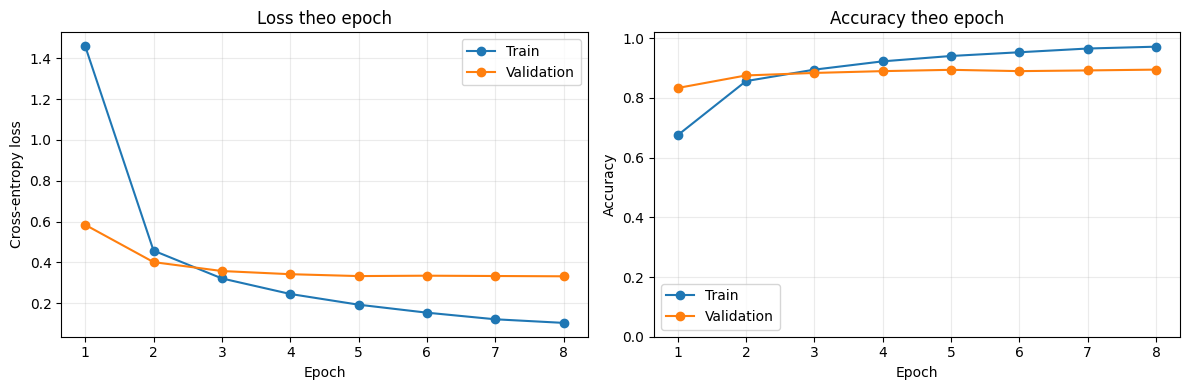

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_df['epoch'], history_df['loss'], marker='o', label='Train')
axes[0].plot(history_df['epoch'], history_df['val_loss'], marker='o', label='Validation')
axes[0].set(title='Loss theo epoch', xlabel='Epoch', ylabel='Cross-entropy loss')
axes[0].legend(); axes[0].grid(alpha=0.25)
axes[1].plot(history_df['epoch'], history_df['accuracy'], marker='o', label='Train')
axes[1].plot(history_df['epoch'], history_df['val_accuracy'], marker='o', label='Validation')
axes[1].set(title='Accuracy theo epoch', xlabel='Epoch', ylabel='Accuracy', ylim=(0, 1.02))
axes[1].legend(); axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

## Evaluation trên tập test

In [11]:
y_true = test_df['label_id'].to_numpy()
y_prob = model.predict(test_ds, verbose=0)
y_pred = y_prob.argmax(axis=1)
num_classes = len(labels)
cm = np.zeros((num_classes, num_classes), dtype=np.int64)
np.add.at(cm, (y_true, y_pred), 1)

tp = np.diag(cm).astype(float)
support = cm.sum(axis=1).astype(float)
predicted_count = cm.sum(axis=0).astype(float)
precision = np.divide(tp, predicted_count, out=np.zeros_like(tp), where=predicted_count != 0)
recall = np.divide(tp, support, out=np.zeros_like(tp), where=support != 0)
f1 = np.divide(2 * precision * recall, precision + recall,
               out=np.zeros_like(tp), where=(precision + recall) != 0)
accuracy = tp.sum() / cm.sum()
macro_precision, macro_recall, macro_f1 = precision.mean(), recall.mean(), f1.mean()
weighted_f1 = np.average(f1, weights=support)

report_df = pd.DataFrame({
    'class': labels, 'precision': precision, 'recall': recall,
    'f1': f1, 'support': support.astype(int),
})
display(report_df.round(4))
metrics = {
    'accuracy': float(accuracy), 'macro_precision': float(macro_precision),
    'macro_recall': float(macro_recall), 'macro_f1': float(macro_f1),
    'weighted_f1': float(weighted_f1), 'best_val_accuracy': best_val_accuracy,
    'best_epoch': best_epoch_index + 1, 'training_seconds': float(training_seconds),
    'test_samples': int(len(y_true)),
}
print(json.dumps(metrics, ensure_ascii=False, indent=2))

,class,precision,recall,f1,support
0,Chinh tri Xa hoi,0.7775,0.8038,0.7904,800
1,Doi song,0.8180,0.6238,0.7078,800
2,Khoa hoc,0.8453,0.8400,0.8426,800
3,Kinh doanh,0.8990,0.8788,0.8887,800
4,Phap luat,0.9046,0.9012,0.9029,800
5,Suc khoe,0.8782,0.9375,0.9069,800
6,The gioi,0.9011,0.9225,0.9117,800
7,The thao,0.9711,0.9675,0.9693,800
8,Van hoa,0.8454,0.9225,0.8822,800
9,Vi tinh,0.9102,0.9625,0.9356,800


{
  "accuracy": 0.876,
  "macro_precision": 0.8750431398479321,
  "macro_recall": 0.876,
  "macro_f1": 0.8738270528876437,
  "weighted_f1": 0.8738270528876437,
  "best_val_accuracy": 0.8950554728507996,
  "best_epoch": 8,
  "training_seconds": 63.81981367399999,
  "test_samples": 8000
}


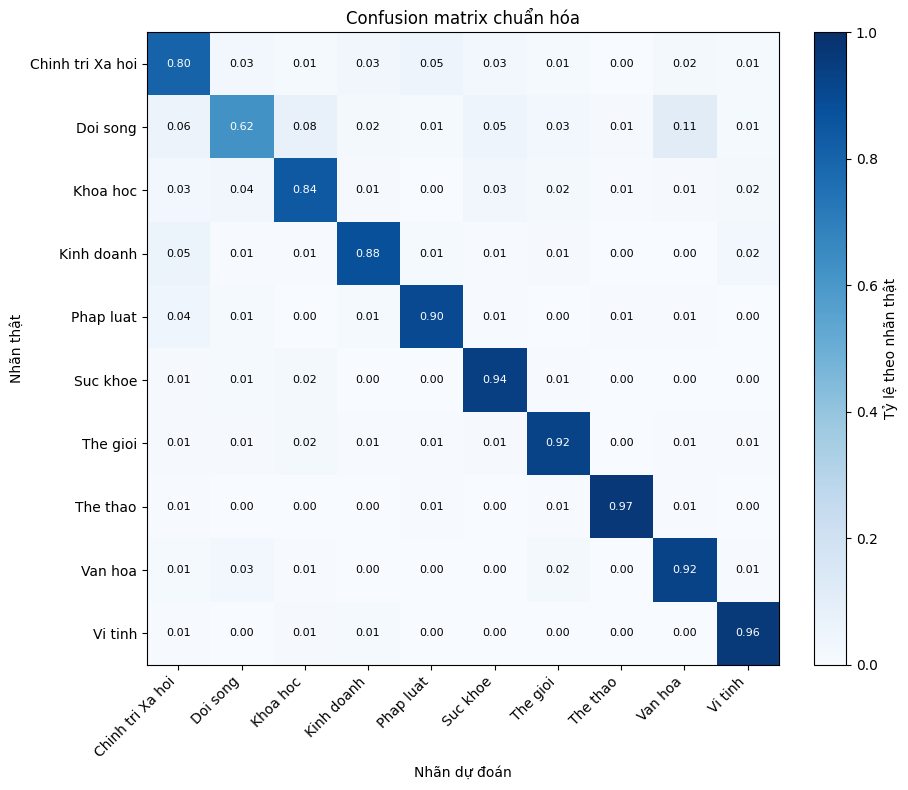

In [12]:
cm_normalized = np.divide(cm, cm.sum(axis=1, keepdims=True),
                          out=np.zeros_like(cm, dtype=float),
                          where=cm.sum(axis=1, keepdims=True) != 0)
fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(cm_normalized, cmap='Blues', vmin=0, vmax=1)
fig.colorbar(image, ax=ax, fraction=0.046, pad=0.04, label='Tỷ lệ theo nhãn thật')
ax.set_xticks(range(num_classes), labels=labels, rotation=45, ha='right')
ax.set_yticks(range(num_classes), labels=labels)
ax.set(xlabel='Nhãn dự đoán', ylabel='Nhãn thật', title='Confusion matrix chuẩn hóa')
for i in range(num_classes):
    for j in range(num_classes):
        value = cm_normalized[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                color='white' if value > 0.5 else 'black', fontsize=8)
plt.tight_layout()
plt.savefig(ARTIFACT_DIR / 'confusion_matrix.png', dpi=150, bbox_inches='tight')
plt.show()

## Error analysis

In [13]:
errors = np.flatnonzero(y_true != y_pred)
if len(errors):
    confidence = y_prob.max(axis=1)
    selected = errors[np.argsort(confidence[errors])[::-1][:10]]
    error_rows = []
    for index in selected:
        error_rows.append({
            'true': id_to_label[int(y_true[index])],
            'predicted': id_to_label[int(y_pred[index])],
            'confidence': float(confidence[index]),
            'text': test_df.iloc[index]['text'][:240].replace('\n', ' '),
        })
    display(pd.DataFrame(error_rows))
else:
    print('Không có dự đoán sai trong tập test đã chọn.')

,true,predicted,confidence,text
0,Doi song,Suc khoe,0.999982,Chân to là do bệnh gì?\r Nếu một chân trở nên ...
1,Suc khoe,The thao,0.999959,'Chuyện ấy' trước giờ thi đấu \r Tại World Cup...
2,Khoa hoc,The thao,0.999916,Tình dục và thể thao\r Một vấn đề có lẽ đã đượ...
3,Chinh tri Xa hoi,The thao,0.999884,TP HCM nhẹ nhàng đón chiến thắng đầu tiên của ...
4,Phap luat,The thao,0.999879,Vũ Tiến Thành đổ tội cho Nguyễn Thành Vinh\r G...
5,Phap luat,The thao,0.999818,Quốc Vượng cũng nằm trong 'tầm ngắm' của công ...
6,Phap luat,Vi tinh,0.999522,Cẩn thận với tin nhắn lừa đảo trên điện thoại ...
7,Phap luat,The thao,0.999460,CLB Đông Á đợi chứng cứ từ cơ quan điều tra\r ...
8,Khoa hoc,Vi tinh,0.999376,Bảng thông minh đi vào trường học Việt Nam\r M...
9,Phap luat,Van hoa,0.999143,“Người mẫu”... nghiệp dư! Sau “phong trào” ca ...


In [14]:
def predict_text(text, top_k=3):
    probabilities = model(tf.constant([text]), training=False).numpy()[0]
    best = np.argsort(probabilities)[::-1][:top_k]
    return [(id_to_label[int(i)], float(probabilities[i])) for i in best]

examples = [
    'Đội tuyển Việt Nam giành chiến thắng sau trận đấu kịch tính trên sân vận động.',
    'Công ty công nghệ ra mắt máy tính mới dùng chip tiết kiệm điện và trí tuệ nhân tạo.',
    'Bộ Y tế khuyến cáo người dân tiêm vaccine và giữ vệ sinh để phòng bệnh.',
]
for text in examples:
    print('\nVăn bản:', text)
    print('Top-3:', predict_text(text))


Văn bản: Đội tuyển Việt Nam giành chiến thắng sau trận đấu kịch tính trên sân vận động.
Top-3: [('The thao', 1.0), ('Van hoa', 3.266273362889649e-10), ('Chinh tri Xa hoi', 1.5893303340064335e-10)]

Văn bản: Công ty công nghệ ra mắt máy tính mới dùng chip tiết kiệm điện và trí tuệ nhân tạo.
Top-3: [('Vi tinh', 0.999751627445221), ('Khoa hoc', 0.00024746591225266457), ('Kinh doanh', 8.27680878501269e-07)]

Văn bản: Bộ Y tế khuyến cáo người dân tiêm vaccine và giữ vệ sinh để phòng bệnh.
Top-3: [('Suc khoe', 0.6910988688468933), ('Phap luat', 0.1943664699792862), ('Chinh tri Xa hoi', 0.09876619279384613)]


## Save model

In [15]:
export_path = ARTIFACT_DIR / 'vntc_tensorflow_saved_model'
if export_path.exists():
    shutil.rmtree(export_path)
model.export(export_path)
history_df.to_csv(ARTIFACT_DIR / 'training_history.csv', index=False)
report_df.to_csv(ARTIFACT_DIR / 'classification_report.csv', index=False)
with (ARTIFACT_DIR / 'metrics.json').open('w', encoding='utf-8') as file:
    json.dump(metrics, file, ensure_ascii=False, indent=2)
with (ARTIFACT_DIR / 'labels.json').open('w', encoding='utf-8') as file:
    json.dump(labels, file, ensure_ascii=False, indent=2)
with (ARTIFACT_DIR / 'vocabulary.json').open('w', encoding='utf-8') as file:
    json.dump(vocabulary, file, ensure_ascii=False)

# Kiểm tra SavedModel sau khi load lại.
reloaded = tf.saved_model.load(str(export_path))
reloaded_probabilities = reloaded.serve(tf.constant([examples[0]])).numpy()[0]
print('Kiểm tra load lại:', id_to_label[int(reloaded_probabilities.argmax())])

print(f"KẾT QUẢ TEST: accuracy={accuracy:.4f}, macro-F1={macro_f1:.4f}, weighted-F1={weighted_f1:.4f}.")
best_class = report_df.loc[report_df['f1'].idxmax()]
weakest_class = report_df.loc[report_df['f1'].idxmin()]
print(f"Lớp tốt nhất theo F1: {best_class['class']} ({best_class['f1']:.4f}).")
print(f"Lớp cần cải thiện nhất: {weakest_class['class']} ({weakest_class['f1']:.4f}).")
print(f"So với đoán ngẫu nhiên cân bằng ({1/len(labels):.0%}), mô hình đạt {accuracy:.1%} accuracy.")
print('Các file đã lưu:')
for path in sorted(ARTIFACT_DIR.iterdir()):
    print(' -', path)

Saved artifact at 'vntc_tensorflow_outputs/vntc_tensorflow_saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None,), dtype=tf.string, name='text')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  138236430538640: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138236430536912: TensorSpec(shape=(), dtype=tf.int64, name=None)
  138235143995216: TensorSpec(shape=(), dtype=tf.string, name=None)
  138236430533456: TensorSpec(shape=(), dtype=tf.int64, name=None)
  138236430543056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138236430542672: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138236430543440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138236430544976: TensorSpec(shape=(), dtype=tf.resource, name=None)
  138236430545936: TensorSpec(shape=(), dtype=tf.resource, name=None)
Kiểm tra load lại: The thao
KẾT QUẢ TEST: accuracy=0.8760, macro-F1=0.8738, wei